# **[실습 3-1] Decision Tree**

##**데이터셋 설명**

| 컬럼명 | 설명 |
|---|---|
| animal_id | 동물 고유 ID |
| body_length_cm | 몸 길이 (cm) |
| weight_kg | 몸무게 (kg) |
| body_size_score | 몸 크기 종합 점수 (몸길이·몸무게 기반 파생 지표) |
| num_legs | 다리 개수 |
| has_fur | 털 보유 여부 (1: 있음, 0: 없음) |
| has_feathers | 깃털 보유 여부 (1: 있음, 0: 없음) |
| has_scales | 비늘 보유 여부 (1: 있음, 0: 없음) |
| lays_eggs | 알을 낳는지 여부 (1: 예, 0: 아니오) |
| is_warm_blooded | 온혈동물 여부 (1: 온혈, 0: 냉혈) |
| lives_in_water | 주로 물에서 서식하는지 여부 (1: 예, 0: 아니오) |
| can_fly | 비행 가능 여부 (1: 예, 0: 아니오) |
| lifespan_years | 평균 수명 (년) |
| top_speed_kmh | 최고 속도 (km/h) |
| habitat | 주요 서식지 (범주형: Forest, Ocean, Grassland, Desert, Wetland, Arctic, Mountain) |
| diet_type | 식성 (범주형: Carnivore, Herbivore, Omnivore) |
| **animal_class** | **(타겟) 동물의 강 - Mammal / Bird / Reptile / Fish / Amphibian** |

## **데이터셋 URL**

https://raw.githubusercontent.com/dukalee/datasets/refs/heads/main/animals.csv

## **1. 데이터 살펴보기**

데이터를 분석하여 인사이트를 찾아내는 과정입니다.
- 각 컬럼이 어떤 의미를 갖는지, 데이터의 전체적인 형태가 어떤지 살펴봅니다.
- 그리고 데이터를 이해하기 위한 여러 정보들을 찾아 csv 형태로 추출하여 채점 사이트에 제출합니다.

**colab에서 csv 파일 다운로드하기**
```
from google.colab import files
files.download("submission.csv")
```

In [1]:
# 저는 설정이 뭔가 안되서 추가하는 코드
from sklearn import set_config
set_config(display="text")

**Q1. 데이터를 불러오고 상위 5개 행을 확인하세요.**

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("https://raw.githubusercontent.com/dukalee/datasets/refs/heads/main/animals.csv")
df.head()

,animal_name,body_length_cm,weight_kg,body_size_score,num_legs,has_fur,has_feathers,has_scales,lays_eggs,is_warm_blooded,lives_in_water,can_fly,lifespan_years,top_speed_kmh,habitat,diet_type,animal_class
0,Lion,260,190.0,348.0,4,1,0,0,0,1,0,0,14.0,80.0,Grassland,Carnivore,Mammal
1,Moose,250,400.0,465.0,4,1,0,0,0,1,0,0,15.0,56.0,Forest,Herbivore,Mammal
2,Gray Wolf,150,40.0,159.0,4,1,0,0,0,1,0,0,8.0,50.0,Forest,Carnivore,Mammal
3,Red Fox,100,5.5,93.3,4,1,0,0,0,1,0,0,4.0,50.0,Forest,Omnivore,Mammal
4,Domestic Cat,46,4.5,44.1,4,1,0,0,0,1,0,0,15.0,48.0,Grassland,Carnivore,Mammal


**Q2. 데이터의 전체적인 구조를 확인하세요.**

In [3]:
# code here
df.shape

(100, 17)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   animal_name      100 non-null    str    
 1   body_length_cm   100 non-null    int64  
 2   weight_kg        100 non-null    float64
 3   body_size_score  100 non-null    float64
 4   num_legs         100 non-null    int64  
 5   has_fur          100 non-null    int64  
 6   has_feathers     100 non-null    int64  
 7   has_scales       100 non-null    int64  
 8   lays_eggs        100 non-null    int64  
 9   is_warm_blooded  100 non-null    int64  
 10  lives_in_water   100 non-null    int64  
 11  can_fly          100 non-null    int64  
 12  lifespan_years   100 non-null    float64
 13  top_speed_kmh    100 non-null    float64
 14  habitat          100 non-null    str    
 15  diet_type        100 non-null    str    
 16  animal_class     100 non-null    str    
dtypes: float64(4), int64(9), str

**Q3. 수치형 컬럼들의 기초 통계량을 확인하세요.**

In [5]:
# code here
df.describe()

,body_length_cm,weight_kg,body_size_score,num_legs,has_fur,has_feathers,has_scales,lays_eggs,is_warm_blooded,lives_in_water,can_fly,lifespan_years,top_speed_kmh
count,100.000000,100.000000,100.000000,100.00000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000
mean,99.410000,70.174980,131.574100,2.52000,0.180000,0.200000,0.340000,0.720000,0.400000,0.440000,0.180000,18.925000,30.727200
std,104.929326,163.052134,177.772956,1.69658,0.386123,0.402015,0.476095,0.451261,0.492366,0.498888,0.386123,16.621055,43.300501
min,3.000000,0.001000,2.700000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.500000,0.020000
25%,20.000000,0.165000,18.035000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9.000000,3.000000
50%,60.000000,2.500000,54.450000,4.00000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,15.000000,16.000000
75%,150.000000,40.000000,172.500000,4.00000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000,0.000000,21.250000,48.500000
max,470.000000,1000.000000,1023.000000,4.00000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,100.000000,320.000000


## **2. 데이터 분석하기**

### **2-1. 데이터 탐색하기**

**Q1. 데이터를 분석하여 다음 정보를 찾아 주세요.**

- 서식지별 동물들의 수를 찾아 주세요.

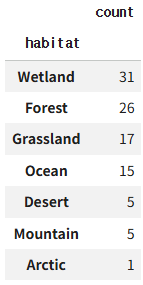

In [6]:
# code here
q1 = df["habitat"].value_counts()
q1.to_csv("submission1.csv")

**Q2. 데이터를 분석하여 다음 정보를 찾아 주세요.**

- 온혈동물 중 각 타겟 클래스에 분포되어있는 동물의 수를 찾아 주세요.

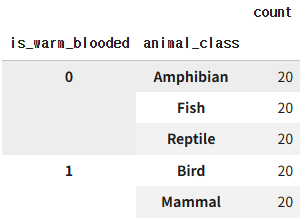

In [7]:
# code here
q2 = df.groupby("is_warm_blooded")["animal_class"].value_counts()
q2.to_csv("submission2.csv")

**Q3. 데이터를 분석하여 다음 정보를 찾아 주세요.**

- 육식동물 중 몸 길이 (body_length_cm)이 가장 긴 5마리의 동물의 이름을 큰 순서대로 저장합니다.

컬럼명은 "animal_name"으로 5마리의 동물명을 저장하여 제출합니다.

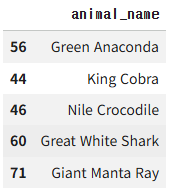

In [8]:
# code here
q3 = df[df["diet_type"] == "Carnivore"].sort_values("body_length_cm", ascending=False)["animal_name"][:5]
q3.to_csv("submission3.csv", index=False)

**Q4. 데이터를 분석하여 다음 정보를 찾아 주세요.**

- 날 수 있으면서 동시에 온혈 동물인 동물들의 비율을 animal_class별로 소수점 2자리까지 구해주세요.

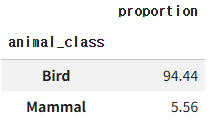

In [9]:
# code here
new_df = df[(df["can_fly"] == 1) & (df["is_warm_blooded"] == 1)]
q4 = (new_df["animal_class"].value_counts(normalize=True) * 100).round(2)
q4.to_csv("submission4.csv")

**Q5. 데이터를 분석하여 다음 정보를 찾아 주세요.**

- 수명이 상위 10%에 해당하는 동물들을 찾아보세요.
- 그리고 이 동물들을 animal_class별 비율을 소수점 2자리까지 구해주세요.

In [10]:
# code here
threshold = df['lifespan_years'].quantile(0.9)
q5 = (df[df['lifespan_years'] >= threshold]['animal_class'].value_counts(normalize=True) * 100).round(2)
q5.to_csv('submission5.csv')

### **2-2. 데이터 시각화하기**

**Q1. 서식지(habitat)별 동물들의 수를 막대 그래프로 그려 주세요.**
- animal_class 별 서식지도 같이 볼 수 있도록 해 주세요.

그리고 이 그래프에서 알 수 있게 된 정보를 코드 아래에 적어 주세요.

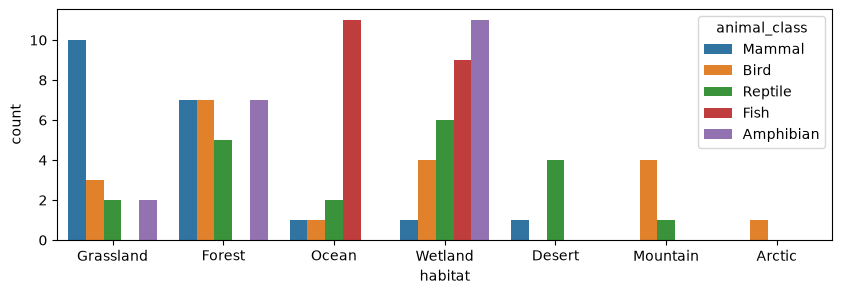

In [11]:
# code here
plt.figure(figsize=(10,3))
sns.countplot(df, x="habitat", hue="animal_class")
plt.show()

**Q2. animal_class별 몸무게 분포를 boxplot으로 시각화하여 이상치를 확인하세요.**

그리고 이 그래프에서 알 수 있게 된 정보를 코드 아래에 적어 주세요.

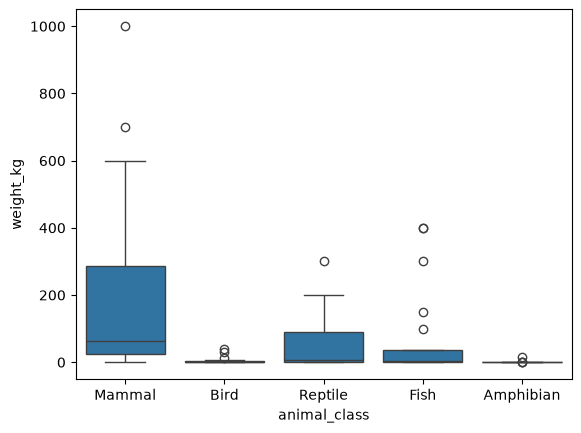

In [12]:
# code here
sns.boxplot(df, x="animal_class", y="weight_kg")
plt.show()

**Q3. body_size_score와 weight_kg의 관계를 scatter plot으로 시각화하세요.**
- animal_class 별로 색을 다르게 표현해주세요.

그리고 이 그래프에서 알 수 있게 된 정보를 코드 아래에 적어 주세요.

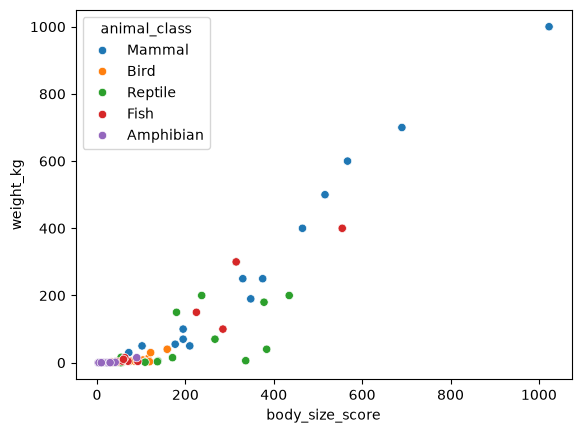

In [13]:
# code here
sns.scatterplot(df, x="body_size_score", y="weight_kg", hue="animal_class")
plt.show()

## **3. 데이터 전처리하기**

In [14]:
# 전처리하다 데이터가 망가지면 여기서부터 재시작!
df = pd.read_csv("https://raw.githubusercontent.com/dukalee/datasets/refs/heads/main/animals.csv")
df.head()

,animal_name,body_length_cm,weight_kg,body_size_score,num_legs,has_fur,has_feathers,has_scales,lays_eggs,is_warm_blooded,lives_in_water,can_fly,lifespan_years,top_speed_kmh,habitat,diet_type,animal_class
0,Lion,260,190.0,348.0,4,1,0,0,0,1,0,0,14.0,80.0,Grassland,Carnivore,Mammal
1,Moose,250,400.0,465.0,4,1,0,0,0,1,0,0,15.0,56.0,Forest,Herbivore,Mammal
2,Gray Wolf,150,40.0,159.0,4,1,0,0,0,1,0,0,8.0,50.0,Forest,Carnivore,Mammal
3,Red Fox,100,5.5,93.3,4,1,0,0,0,1,0,0,4.0,50.0,Forest,Omnivore,Mammal
4,Domestic Cat,46,4.5,44.1,4,1,0,0,0,1,0,0,15.0,48.0,Grassland,Carnivore,Mammal


### **3-1. 데이터 분리하기**

**Q1. animal_class를 타겟으로 하여 학습용(train)과 테스트용(test) 데이터로 분리하세요.**
- 비율: 7(학습) : 3(테스트)
- random_state = 101


이번 문항은 클래스가 여러개이며, 데이터의 개수가 충분하지 않은 편이다.
- 학습-테스트 데이터를 불균형하게나누면, 특정 class는 절대로 예측하지 못하는 모델이 생성될 수 있다.
- 최대한 클래스의 비율을 유지하면서 데이터를 나눌수 있도록, "stratify"옵션을 활용한다.

```
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=101, stratify=y)
```

In [15]:
X = df.drop("animal_class", axis=1)
y = df["animal_class"]

In [16]:
# code here
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=101, stratify=y)

### **3-2. 결측치 처리하기**

이번 데이터는 결측치가 존재하지 않는다.

### **3-3. 이상치 처리하기**

이번 데이터에는 이상치가 존재하지 않는다.
- 이상치라고 IQR로 판단되더라도, 실제 동물의 정보일 뿐이다.

### **3-4. 범주형 변수 인코딩**

**Q1. 범주형 변수(habitat, diet_type)를 One-Hot 인코딩하세요.**
- "Arctic" habitat에 사는 동물은 하나밖에 없습니다. (어떻게 보면 이상치 또는 데이터 부실)

OneHotEncoder에서 handle_unknown옵션을 "ignore"로 설정해 주세요.

```
ohe = OneHotEncoder(sparse_output=False, drop="first", handle_unknown="ignore")
```


In [17]:
# code here
from sklearn.preprocessing import OneHotEncoder

ohe = OneHotEncoder(sparse_output=False, drop="first", handle_unknown="ignore")
# 인코딩해야 할 열은 2개입니다. (habitat, diet type)
cols = ["habitat", "diet_type"]

In [18]:
X_train_encoded = pd.DataFrame(
    ohe.fit_transform(X_train[cols]), 
    columns=ohe.get_feature_names_out(),
    index = X_train.index)

In [19]:
X_test_encoded = pd.DataFrame(
    ohe.transform(X_test[cols]), 
    columns=ohe.get_feature_names_out(),
    index = X_test.index)

c:\Users\user\AppData\Local\Programs\Python\Python315\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


In [20]:
X_train_encoded = pd.concat([X_train.drop(cols, axis=1), X_train_encoded], axis=1)

In [21]:
X_test_encoded = pd.concat([X_test.drop(cols, axis=1), X_test_encoded], axis=1)

In [22]:
# 이름은 이제 필요 없으니까 두쪽에서 다 이름 열은 삭제
X_train_encoded = X_train_encoded.drop("animal_name", axis=1)

In [23]:
X_test_encoded = X_test_encoded.drop("animal_name", axis=1)

## **4. 모델링**

### **4-1. 모델 학습**

**Q1. 결정 트리 모델을 생성하세요.**

- criterion = "entropy", max_depth=2, min_samples_leaf=3 로 설정해 봅시다.


In [24]:
# code here
from sklearn.tree import DecisionTreeClassifier
model = DecisionTreeClassifier(
    criterion="entropy",
    max_depth=2,
    min_samples_leaf=3
)

**Q2. 모델을 전처리된 데이터로 학습시켜 주세요.**

In [25]:
# code here
model.fit(X_train_encoded, y_train)

DecisionTreeClassifier(criterion='entropy', max_depth=2, min_samples_leaf=3)

### **4-2. 모델 예측**

**Q1. 예측 결과를 y_pred에 저장합니다.**

In [26]:
# code here
y_pred = model.predict(X_test_encoded)

### **4-3. 모델 평가**

**Q1.정확도, classification report, confusion matrix로 모델의 성능을 평가합니다.**

In [27]:
# code here
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
print(f"accuracy : {accuracy_score(y_test, y_pred)}")

accuracy : 0.8


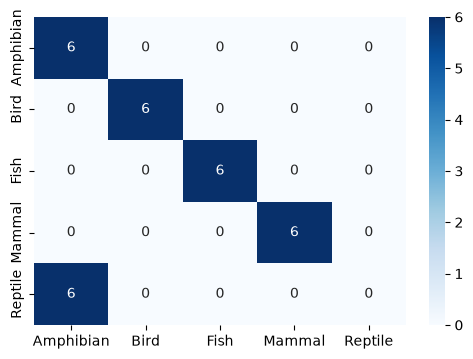

In [28]:
plt.figure(figsize=(6,4))
sns.heatmap(confusion_matrix(y_test, y_pred),annot=True,cmap="Blues", 
            xticklabels=model.classes_, yticklabels=model.classes_) 
plt.show() 

### **4-4. 트리 구조 시각화**

**Q1. plot_tree를 이용해 학습된 의사결정나무의 구조를 시각화하세요.**

In [29]:
model.classes_

array(['Amphibian', 'Bird', 'Fish', 'Mammal', 'Reptile'], dtype=object)

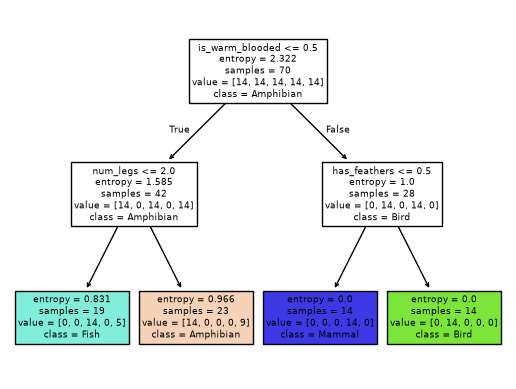

In [30]:
# code here
from sklearn.tree import plot_tree
# plot_tree(모델, feature_names)
plot_tree(model, feature_names=X_train_encoded.columns, class_names=model.classes_, filled=True)
plt.show()

### **4-5. 피처 중요도(Feature Importance) 확인**

**Q1. 학습된 모델의 어떤 피처가 분류에 가장 중요했는지 시각화하세요.**
- 모델의 feature_importances_를 활용해 주세요.

In [31]:
# code here
feature_importances = pd.Series(model.feature_importances_, index=X_train_encoded.columns)
feature_importances = feature_importances.sort_values(ascending=False)

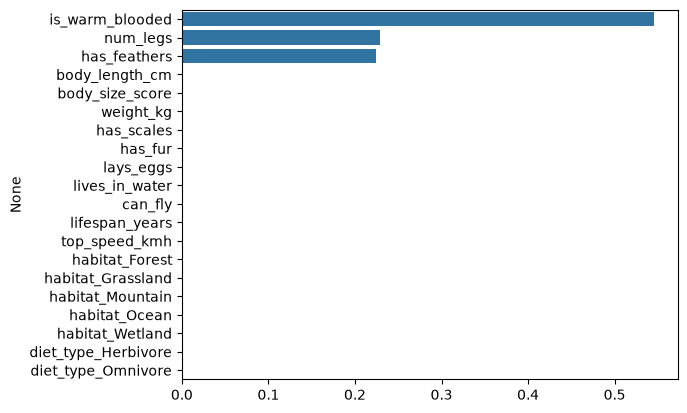

In [32]:
sns.barplot(x=feature_importances.values, y=feature_importances.index)
plt.show()

# **[실습 3-2] Cross Validation**

## **5. Cross Validation**

### **5-1. GridSearch CV**

**Q1. GridSearch CV를 통해 최적의 하이퍼파라미터를 찾아보세요 .**

param_grid는 다음과 같이 설정합니다.
- max_depth : 3, 5, 7, 10
- min_samples_split : 2, 5, 10,
- criterion : "gini", "entropy"

In [33]:
# code here
from sklearn.model_selection import GridSearchCV

# search space 
param_grid = {
    # hyperparameter = [이런 이런 옵션] -> 딕셔너리의 형태로 넣어준다.
    "max_depth" : [3, 5, 7, 10],
    "min_samples_split" : [2, 5, 10],
    "criterion" : ["gini", "entropy"]
}

In [34]:
grid_search = GridSearchCV(
    # 1. estimator = model
    estimator = DecisionTreeClassifier(),
    # 2. search space
    param_grid = param_grid,
    # 3. cross validation에 대한 옵션 (default : stratified k-fold로 잡혀있다)
    cv = 5,
    # 4. verbose : 학습 현황을 어떻게 표기할거냐
    verbose=1
)

In [35]:
grid_search.fit(X_train_encoded, y_train)

Fitting 5 folds for each of 24 candidates, totalling 120 fits


GridSearchCV(cv=5, estimator=DecisionTreeClassifier(),
             param_grid={'criterion': ['gini', 'entropy'],
                         'max_depth': [3, 5, 7, 10],
                         'min_samples_split': [2, 5, 10]},
             verbose=1)

**Q2. Grid Search로 찾은 최고 점수를 출력합니다.**
- Default 성능 평가 점수는 "accuracy" 입니다.

```
grid_search.best_score_
```

In [36]:
# code here
print(grid_search.best_score_)

0.9571428571428571


**Q3. Grid Search로 찾은 최상의 hyperparameter를 출력합니다.**

```
grid_search.best_params_
```

In [37]:
# code here
print(grid_search.best_params_)

{'criterion': 'entropy', 'max_depth': 3, 'min_samples_split': 10}


**Q4. Grid Search로 생성된 최상의 하이퍼파라미터를 탑재한 모델을 출력합니다.**

```
grid_search.best_estimator_
```

In [38]:
# code here
model = grid_search.best_estimator_ 

### **5-2. 모델 예측**

**Q1. 최상의 하이퍼파라미터가 탑재된 모델을 활용해서 X_test에 대한 예측 결과를 냅니다.**

In [39]:
# code here
y_pred = model.predict(X_test_encoded)

### **5-3. 모델 평가**

**Q1.정확도, classification report, confusion matrix로 모델의 성능을 평가합니다.**

In [40]:
# code here
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
print(f"accuracy : {accuracy_score(y_test, y_pred)}")

accuracy : 1.0


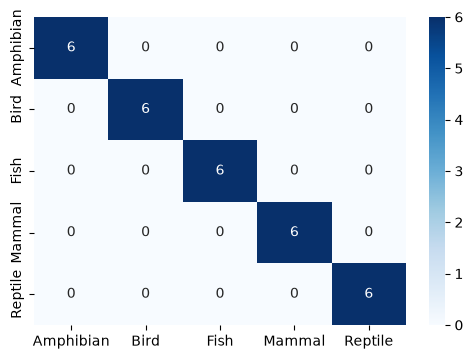

In [41]:
plt.figure(figsize=(6,4))
sns.heatmap(confusion_matrix(y_test, y_pred),annot=True,cmap="Blues", 
            xticklabels=model.classes_, yticklabels=model.classes_) 
plt.show() 

### **5-4. 트리 구조 시각화**

**Q1. plot_tree를 이용해 학습된 의사결정나무의 구조를 시각화하세요.**

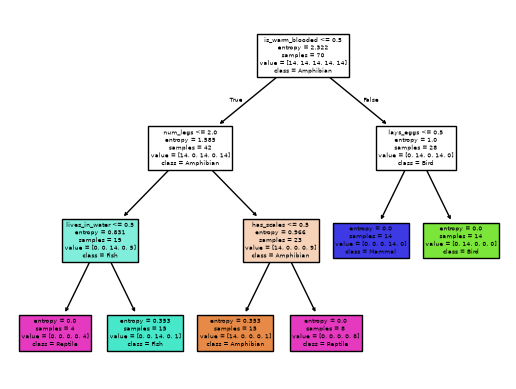

In [42]:
# code here
from sklearn.tree import plot_tree
# plot_tree(모델, feature_names)
plot_tree(model, feature_names=X_train_encoded.columns, class_names=model.classes_, filled=True)
plt.show()

### **5-5. 피처 중요도(Feature Importance) 확인**

**Q1. 학습된 모델의 어떤 피처가 분류에 가장 중요했는지 시각화하세요.**

- 모델의 feature_importances_를 활용해 주세요.

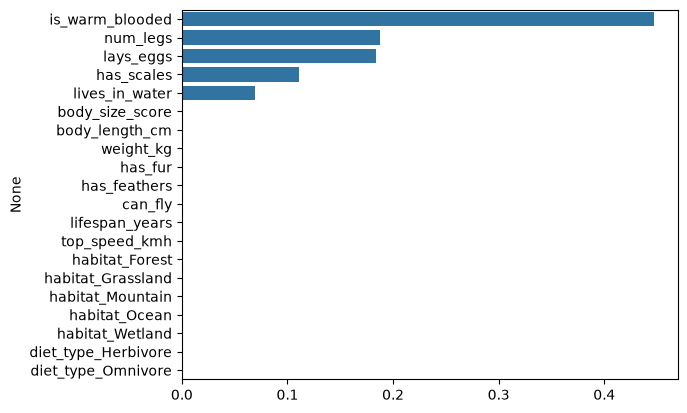

In [43]:
# code here
feature_importances = pd.Series(model.feature_importances_, index=X_train_encoded.columns)
feature_importances = feature_importances.sort_values(ascending=False)
sns.barplot(x=feature_importances.values, y=feature_importances.index)
plt.show()

## **6. 채점하기**

데이터 전처리 방법과 학습된 모델을 활용하여 미공개 데이터에 대한 분류 예측 결과를 "animal_class" 컬럼에 순서대로 저장하고, 제출합니다.

**미공개 데이터 URL:**

https://raw.githubusercontent.com/dukalee/datasets/refs/heads/main/animals_submission.csv

In [44]:
submission = pd.read_csv("https://raw.githubusercontent.com/dukalee/datasets/refs/heads/main/animals_submission.csv")
submission.head()

,animal_name,body_length_cm,weight_kg,body_size_score,num_legs,has_fur,has_feathers,has_scales,lays_eggs,is_warm_blooded,lives_in_water,can_fly,lifespan_years,top_speed_kmh,habitat,diet_type
0,Polar Bear,250,450.0,495.0,4,1,0,0,0,1,0,0,25,40.0,Arctic,Carnivore
1,Snow Leopard,115,45.0,130.5,4,1,0,0,0,1,0,0,15,55.0,Mountain,Carnivore
2,Orca,700,5000.0,3630.0,0,0,0,0,0,1,1,0,50,54.0,Ocean,Carnivore
3,Platypus,45,1.5,41.4,4,1,0,0,1,1,1,0,11,6.0,Wetland,Carnivore
4,European Hedgehog,25,1.0,23.1,4,0,0,0,0,1,0,0,5,6.0,Grassland,Omnivore


In [45]:
# 미공개 데이터 불러오기
submission = pd.read_csv(
    "https://raw.githubusercontent.com/dukalee/datasets/refs/heads/main/animals_submission.csv"
)

# 학습 때 사용한 인코더로 habitat, diet_type 변환
submission_array = ohe.transform(submission[cols])

submission_encoded = pd.DataFrame(
    submission_array,
    columns=ohe.get_feature_names_out(),
    index=submission.index
)

# 원래 범주형 열을 인코딩한 열로 교체
X_submission_final = pd.concat(
    [submission.drop(columns=cols), submission_encoded],
    axis=1
)

# 학습 때 입력에서 제외했던 동물 이름도 제거하고,
# 학습 데이터의 열 이름과 순서에 맞춤
X_submission_final = X_submission_final.drop(columns=["animal_name"])
X_submission_final = X_submission_final.reindex(columns=X_train_final.columns)

# GridSearchCV까지 실행했다면 best_model로 예측
submission["animal_class"] = best_model.predict(X_submission_final)

# 결과 확인 및 CSV 저장
display(submission[["animal_name", "animal_class"]].head())
submission.to_csv("submission.csv", index=False)

c:\Users\user\AppData\Local\Programs\Python\Python315\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


NameError: name 'X_train_final' is not defined